# Medical Insurance Charges – Exploratory Data Analysis (EDA)

**Goal:** Find out which factors (age, BMI, smoking, region, etc.) affect medical insurance charges, and prepare the data for a Machine Learning model.

**Dataset:** Medical Insurance dataset – 1,338 rows, 7 columns

| Column | Meaning |
|---|---|
| `age` | Age of the person |
| `sex` | male / female |
| `bmi` | Body Mass Index |
| `children` | Number of children covered by the insurance |
| `smoker` | yes / no |
| `region` | US region (northeast, northwest, southeast, southwest) |
| `charges` | Medical insurance cost (**target variable**) |

**Steps**
1. Exploratory Data Analysis (EDA)
2. Data Cleaning and Preprocessing
3. Feature Engineering and Extraction
4. Feature Selection (Pearson correlation & Chi-square test)
5. Key Insights

### Importing libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


### Loading the dataset

In [2]:
df = pd.read_csv('insurance.csv', encoding='latin1')

In [3]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


**EDA**

### Data overview
Shape, data types and summary statistics of the dataset.

In [4]:
df.shape


(1338, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### Missing values

In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

### Distribution of numeric columns
Histograms with a KDE curve show the shape of each numeric column.

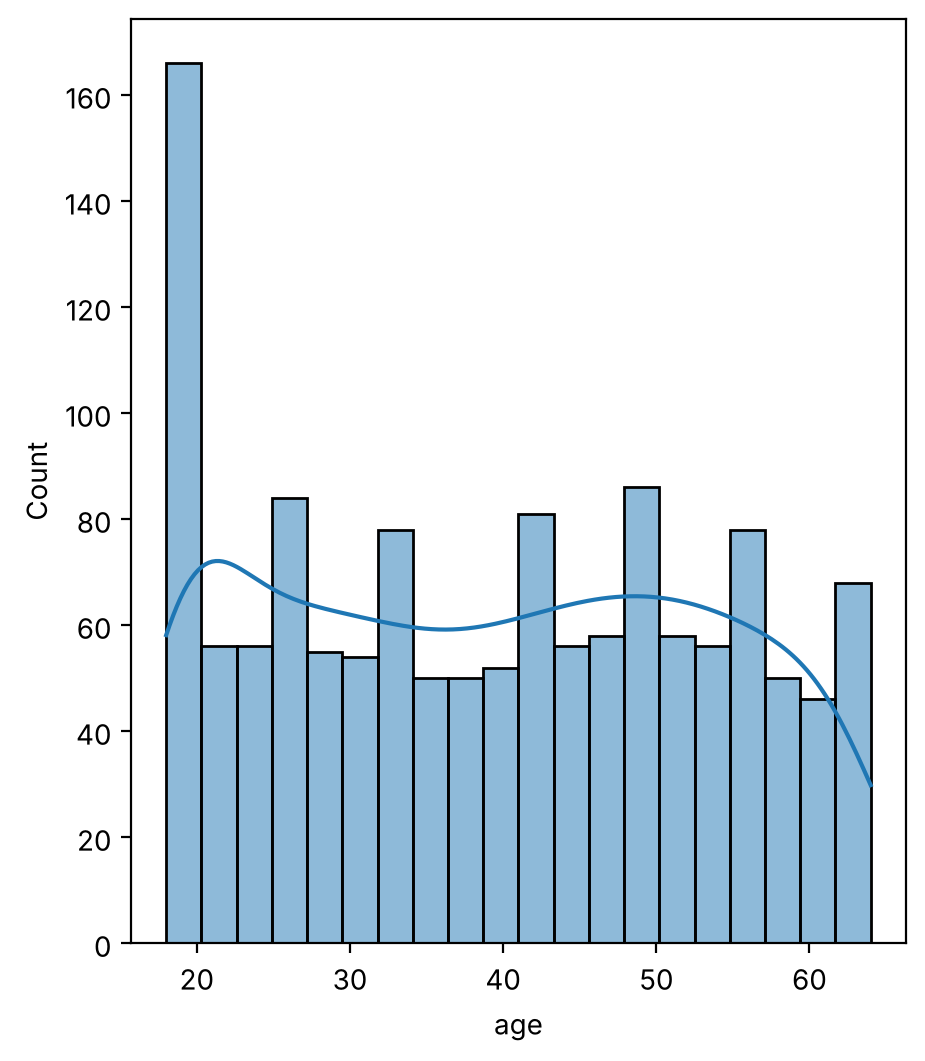

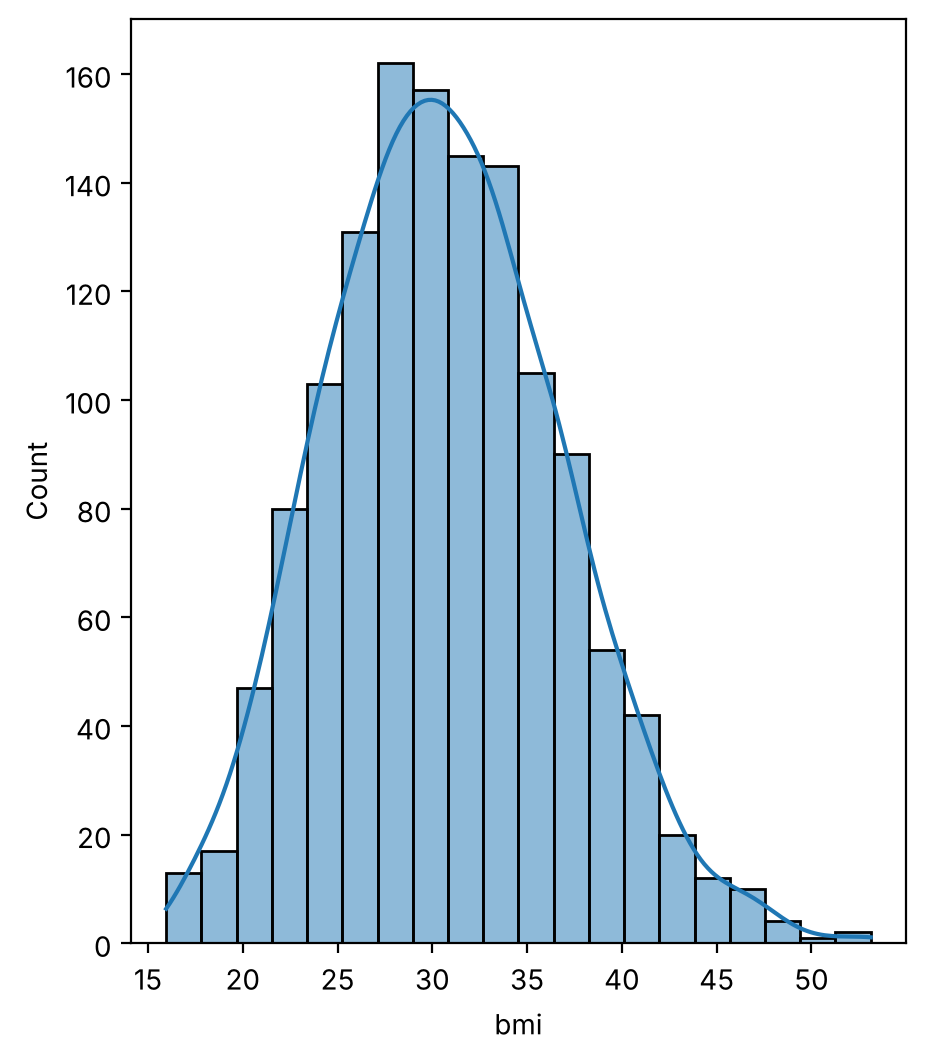

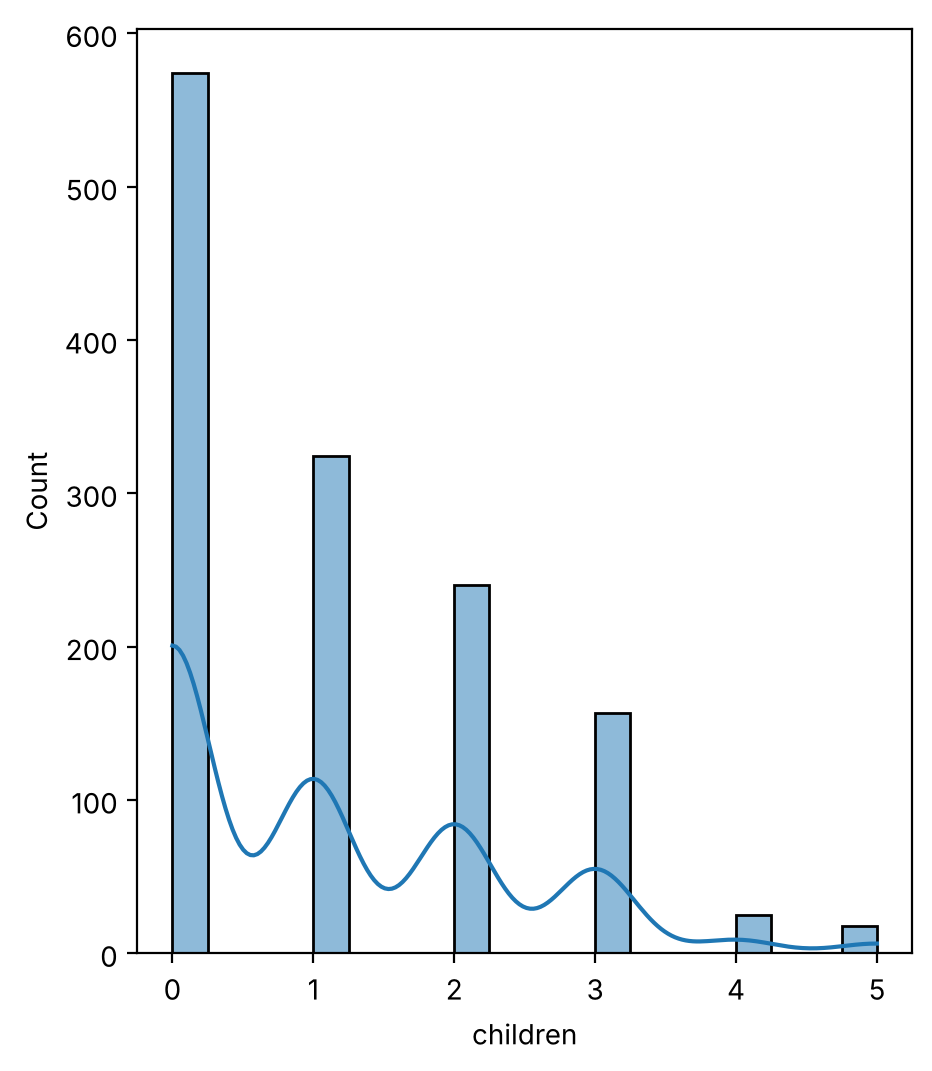

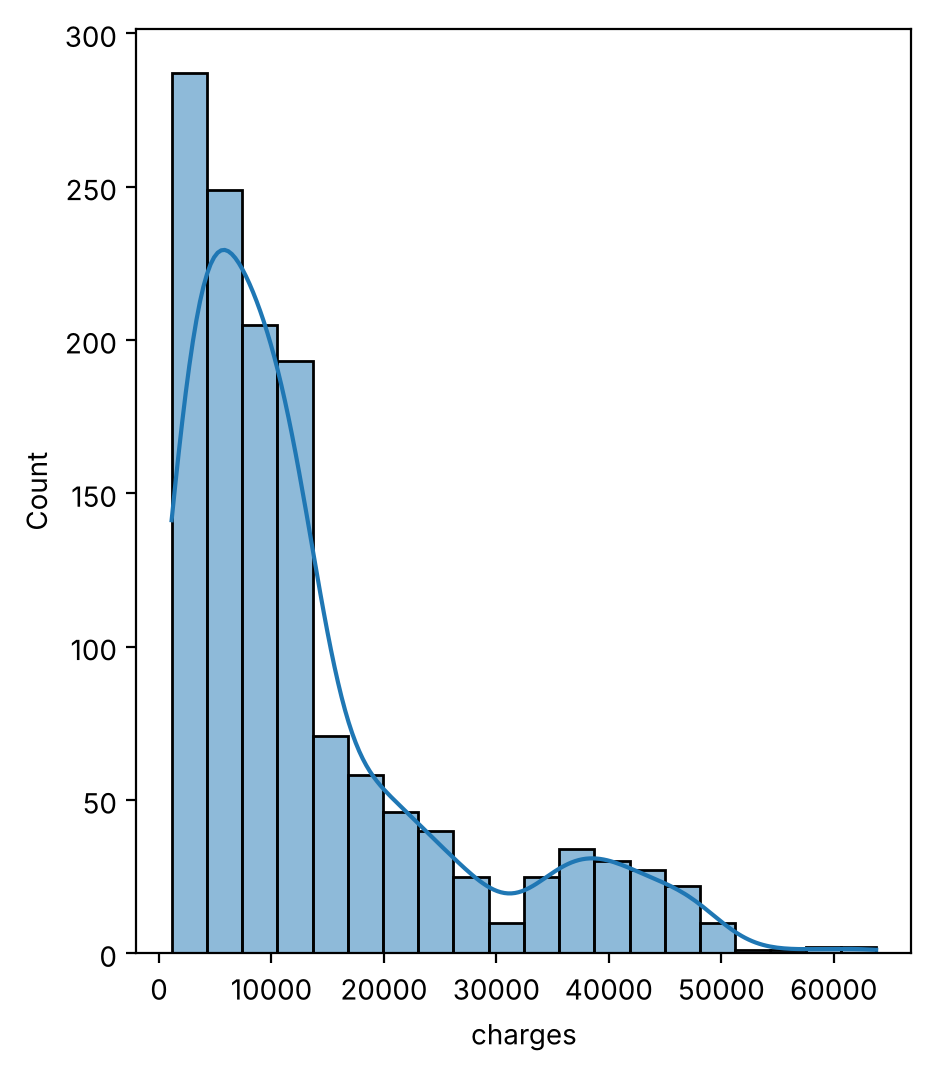

In [9]:
numeric_columns=['age','bmi','children','charges']
for col in numeric_columns:
    plt.figure(figsize=(5,6))
    sns.histplot(df[col],kde=True,bins=20)

**Observation:** `bmi` is close to a normal distribution, while `charges` is right-skewed – most people pay low charges and a few pay very high charges.

### Count of categorical columns

<Axes: xlabel='children', ylabel='count'>

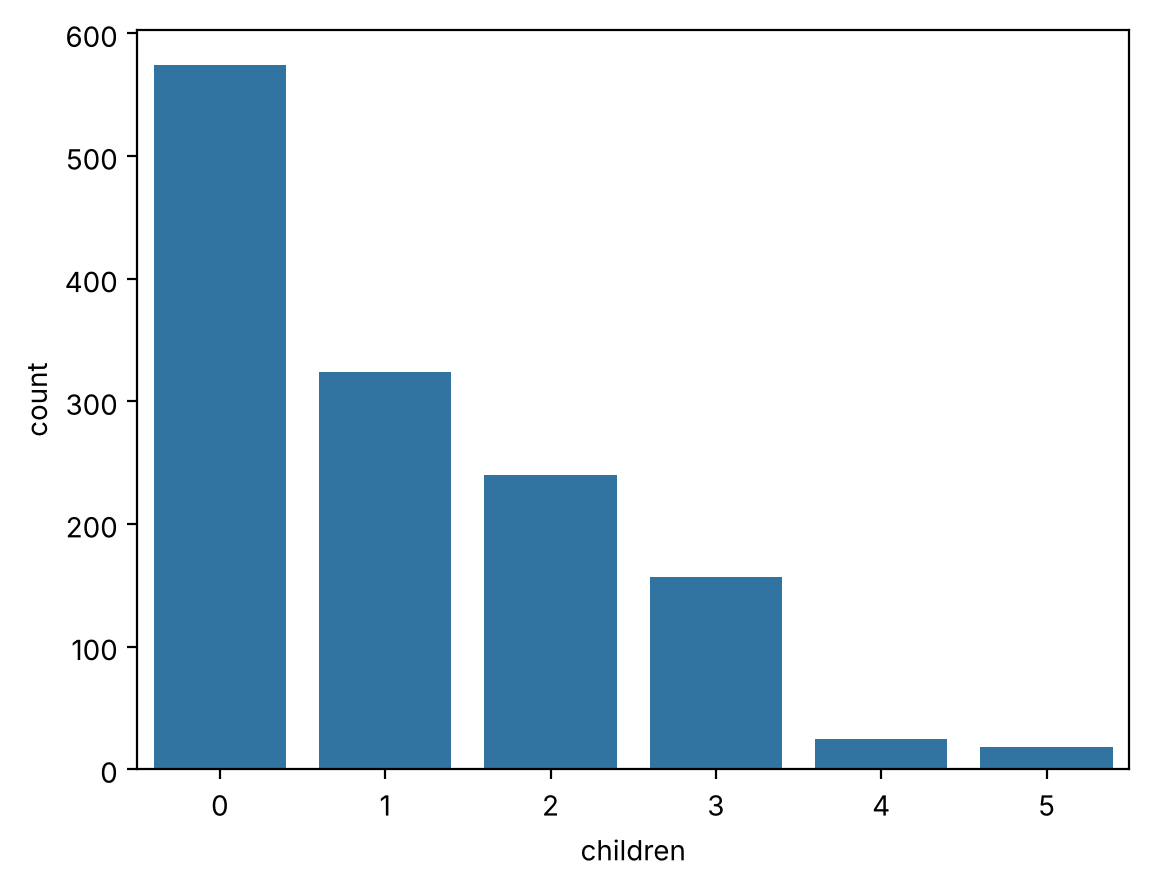

In [10]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

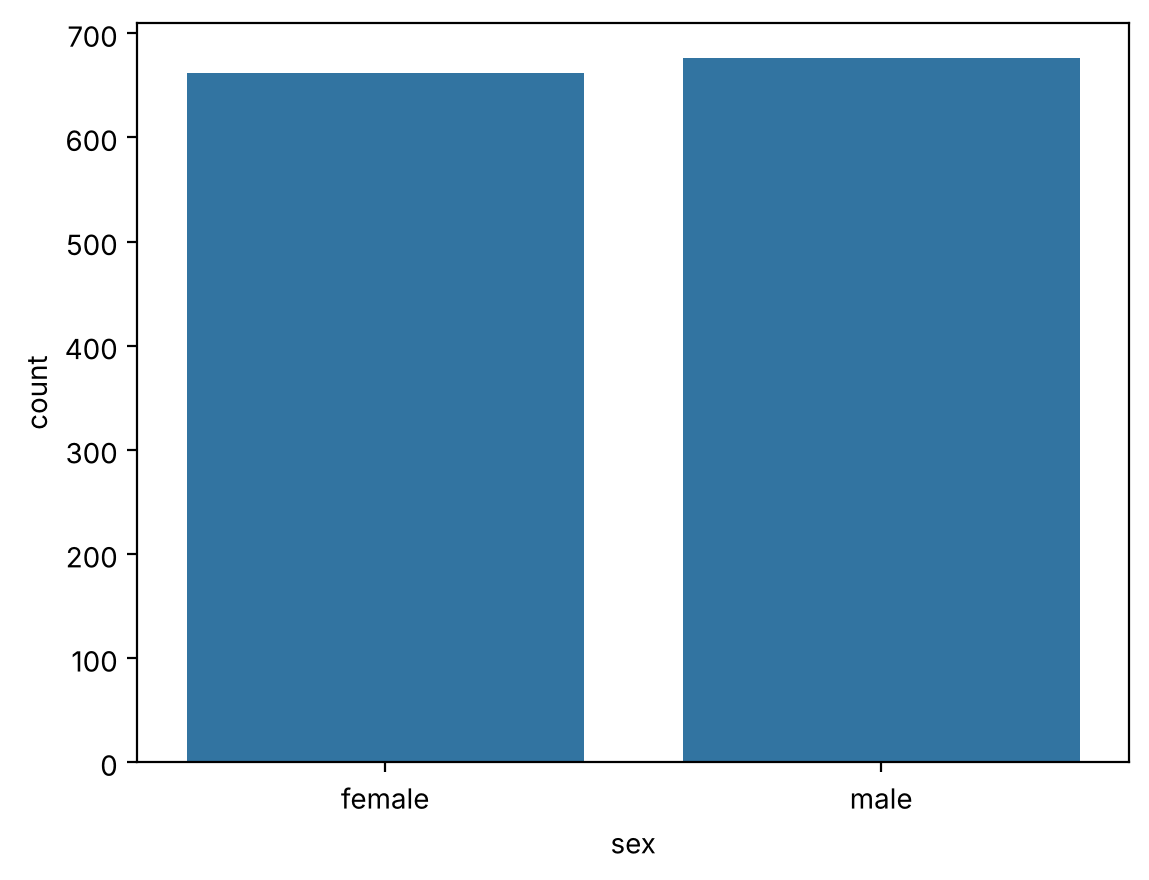

In [11]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

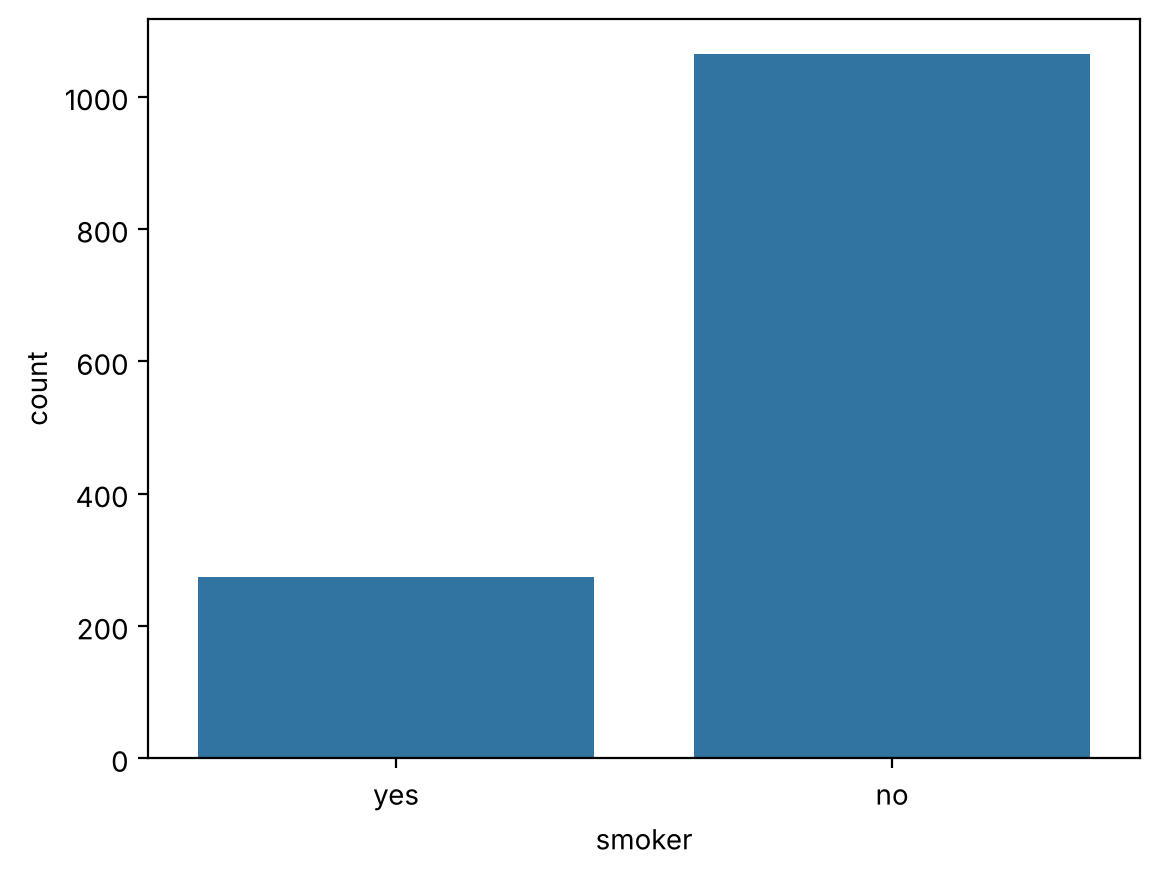

In [12]:
sns.countplot(x=df['smoker'])

<Axes: xlabel='region', ylabel='count'>

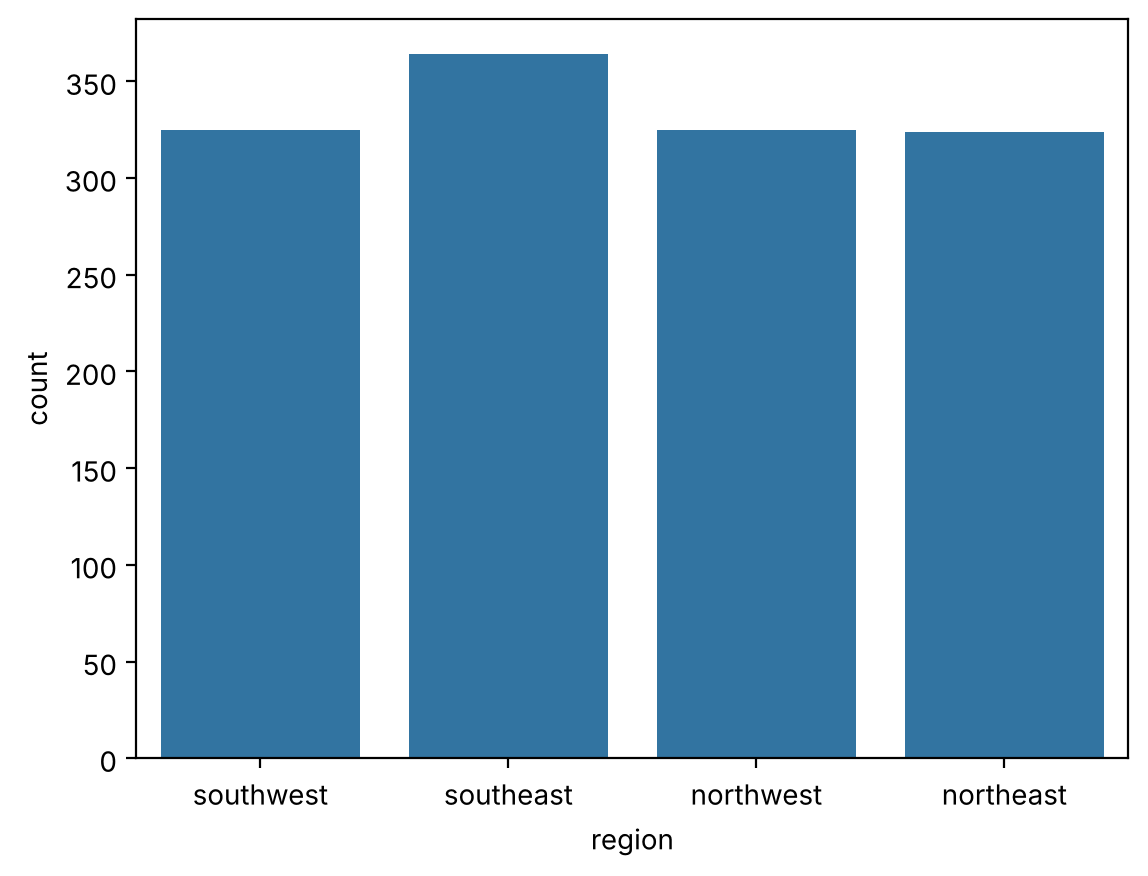

In [13]:
sns.countplot(x=df['region'])

**Observation:** `sex` and `region` are almost equally balanced. Most people (about 80%) are non-smokers.

### Outlier detection (boxplots)

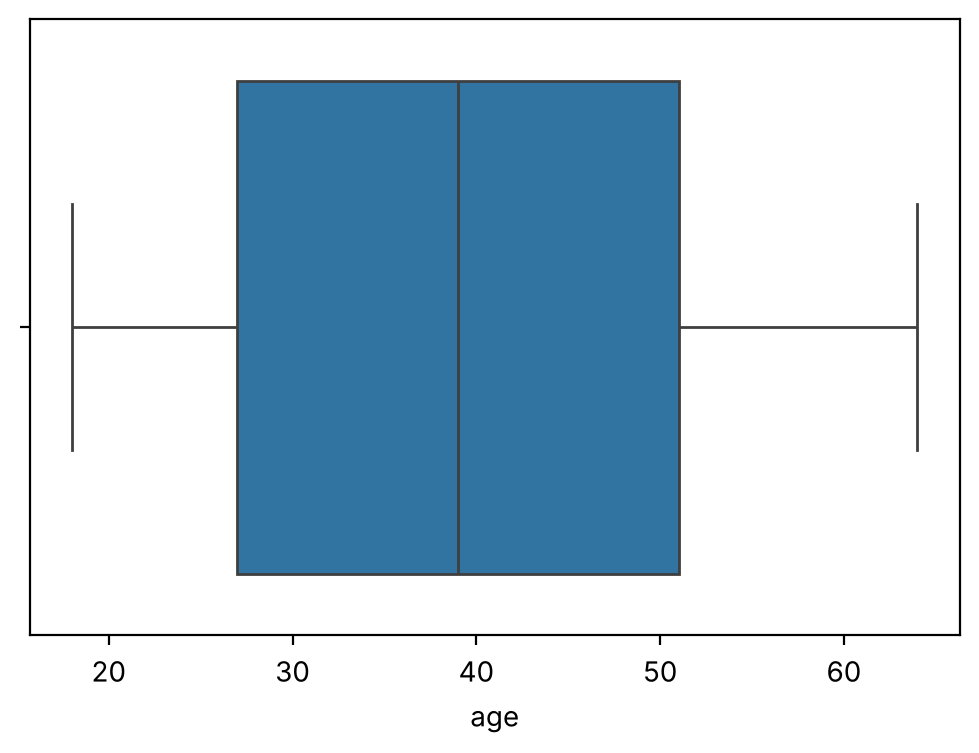

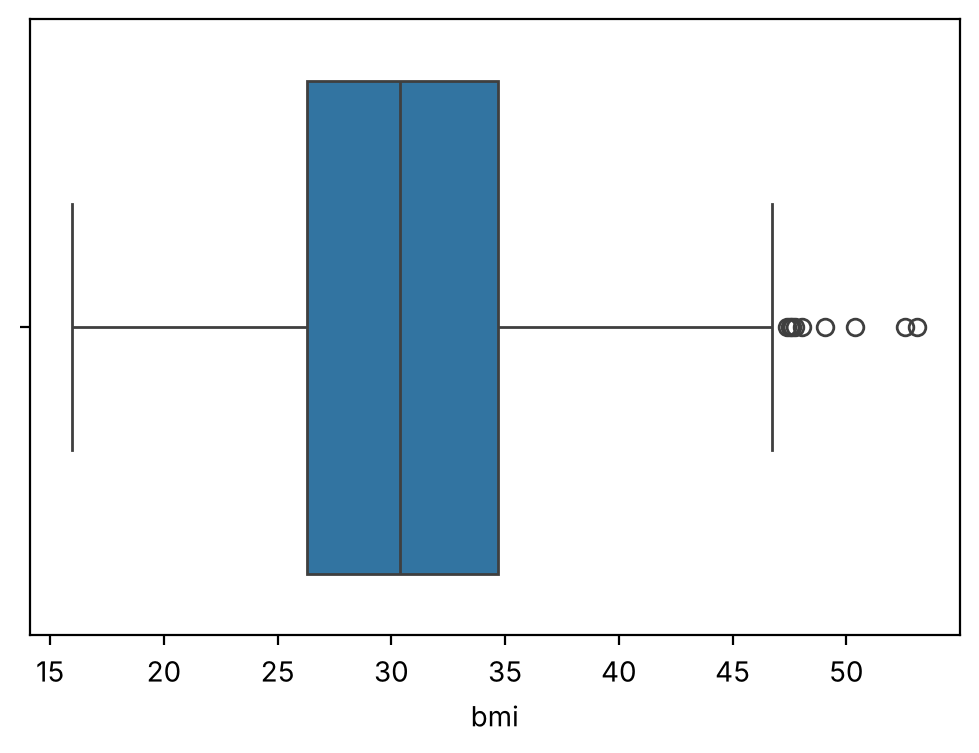

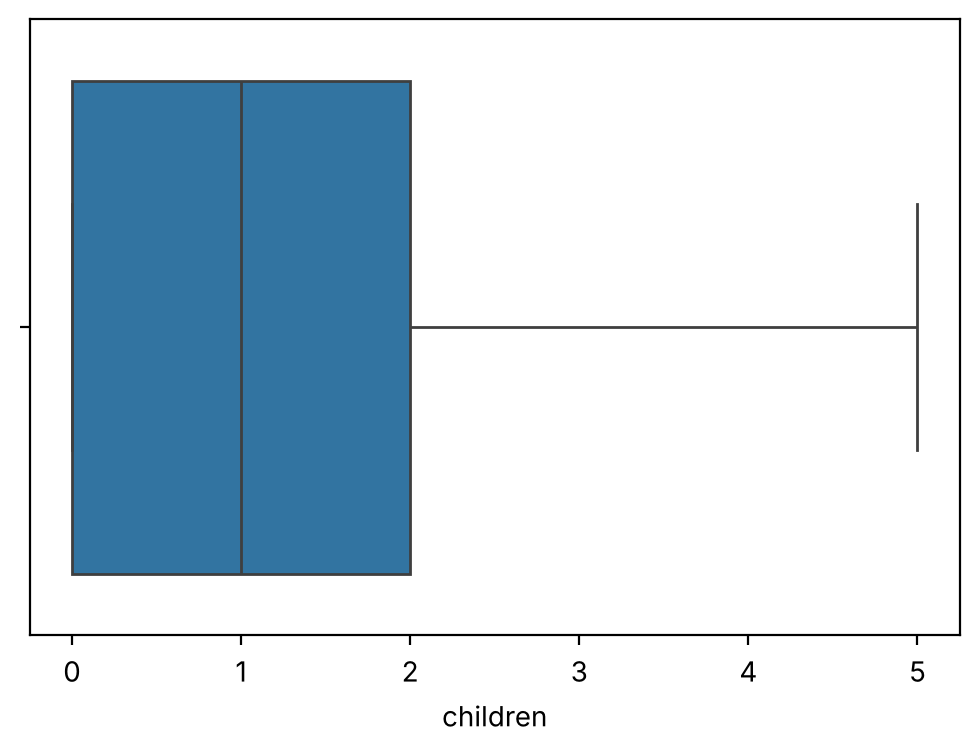

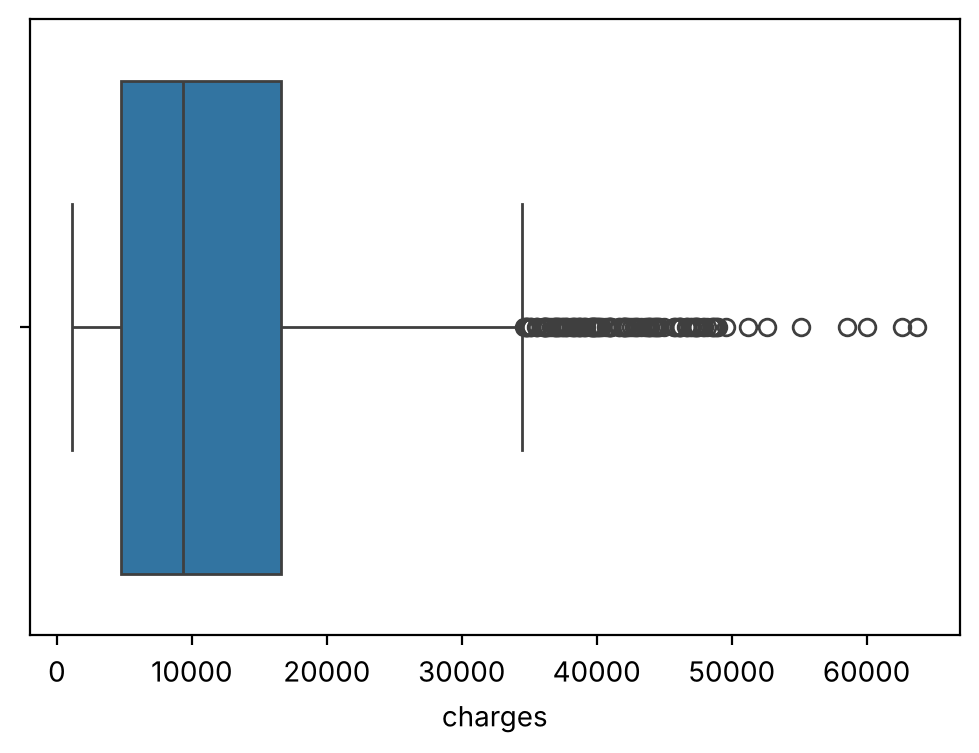

In [14]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

**Observation:** `bmi` and `charges` have some outliers. High charges are real values (expensive patients), so they are kept.

### Correlation heatmap

<Axes: >

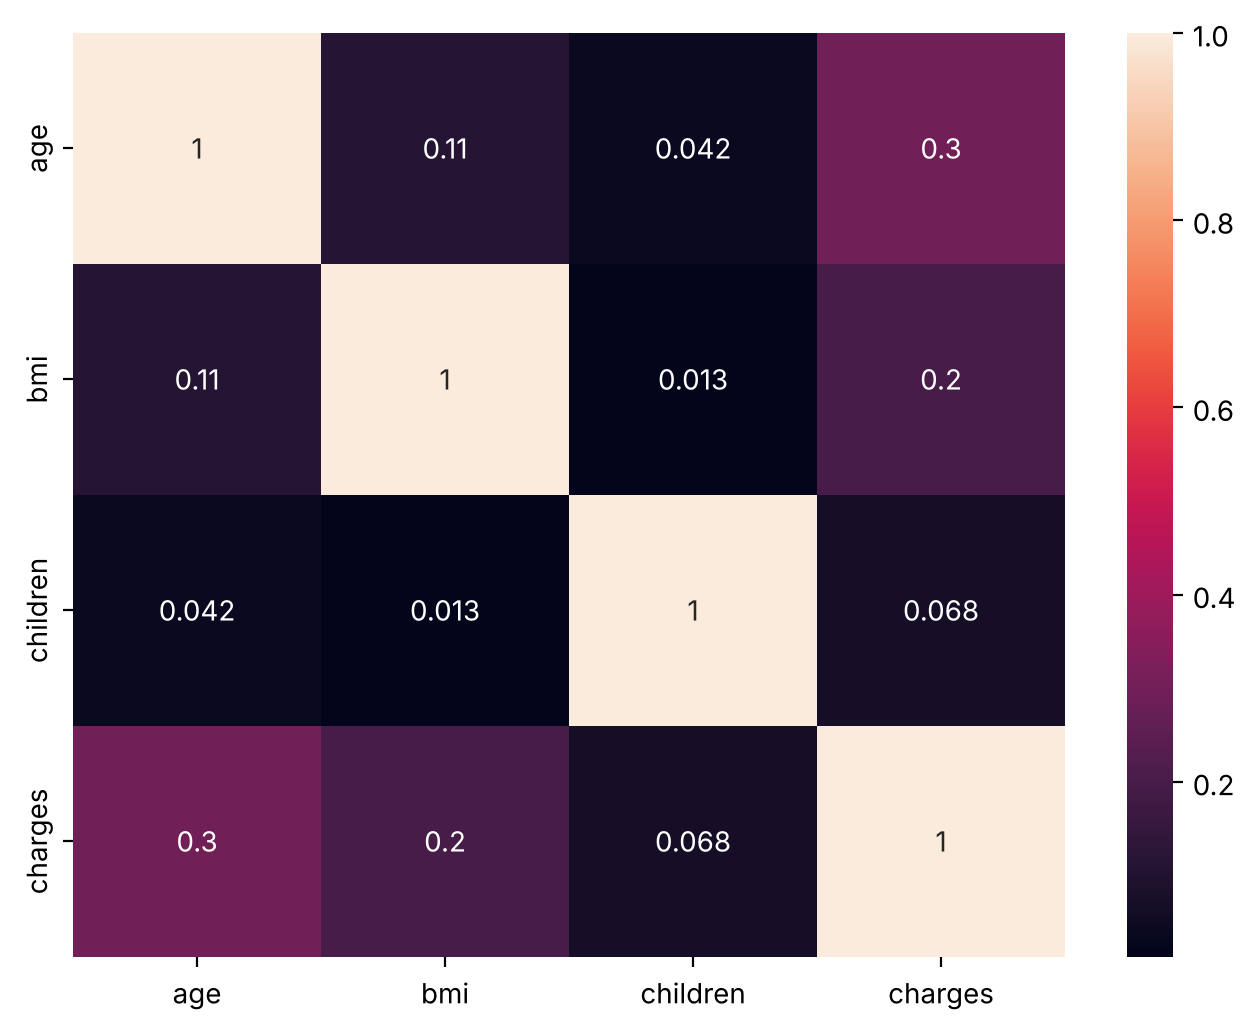

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

**Observation:** Among numeric columns, `age` has the strongest correlation with `charges`.

**Data Cleaning and Preprocessing**

In [16]:
df_cleaned=df.copy()

In [17]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [18]:
df_cleaned.shape

(1338, 7)

### Removing duplicates

In [19]:
df_cleaned.drop_duplicates(inplace = True)

In [20]:
df_cleaned.shape

(1337, 7)

### Encoding categorical columns
`sex` and `smoker` are converted to 0/1 so that a model can use them.

In [21]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [22]:
df_cleaned['sex']=df_cleaned['sex'].map({'male':0,'female':1})

In [23]:
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830
1334,18,1,31.920,0,no,northeast,2205.98080
1335,18,1,36.850,0,no,southeast,1629.83350
1336,21,1,25.800,0,no,southwest,2007.94500


In [24]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [25]:
df_cleaned['smoker']=df_cleaned['smoker'].map({'no':0,'yes':1})

In [26]:
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


Renaming the columns so that the meaning of 1 is clear.

In [27]:
df_cleaned.rename(columns={'sex' :'is_female','smoker': 'is_smoker'},inplace = True)

### One-hot encoding `region`
`region` has 4 categories, so one 0/1 column is created per region. `drop_first=True` drops one column (northeast) to avoid duplicate information.

In [28]:
df_cleaned['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [29]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['region'],drop_first=True)

In [30]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,True,False,False
1334,18,1,31.920,0,0,2205.98080,False,False,False
1335,18,1,36.850,0,0,1629.83350,False,True,False
1336,21,1,25.800,0,0,2007.94500,False,False,True


Converting the True/False region columns to 0/1.

In [31]:
df_cleaned=df_cleaned.astype({'region_northwest':int,'region_southeast':int,'region_southwest':int})

In [32]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,1
1,18,0,33.770,1,0,1725.55230,0,1,0
2,28,0,33.000,3,0,4449.46200,0,1,0
3,33,0,22.705,0,0,21984.47061,1,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0
1334,18,1,31.920,0,0,2205.98080,0,0,0
1335,18,1,36.850,0,0,1629.83350,0,1,0
1336,21,1,25.800,0,0,2007.94500,0,0,1


**Feature Engineering and Extraction**

<Axes: xlabel='bmi', ylabel='Count'>

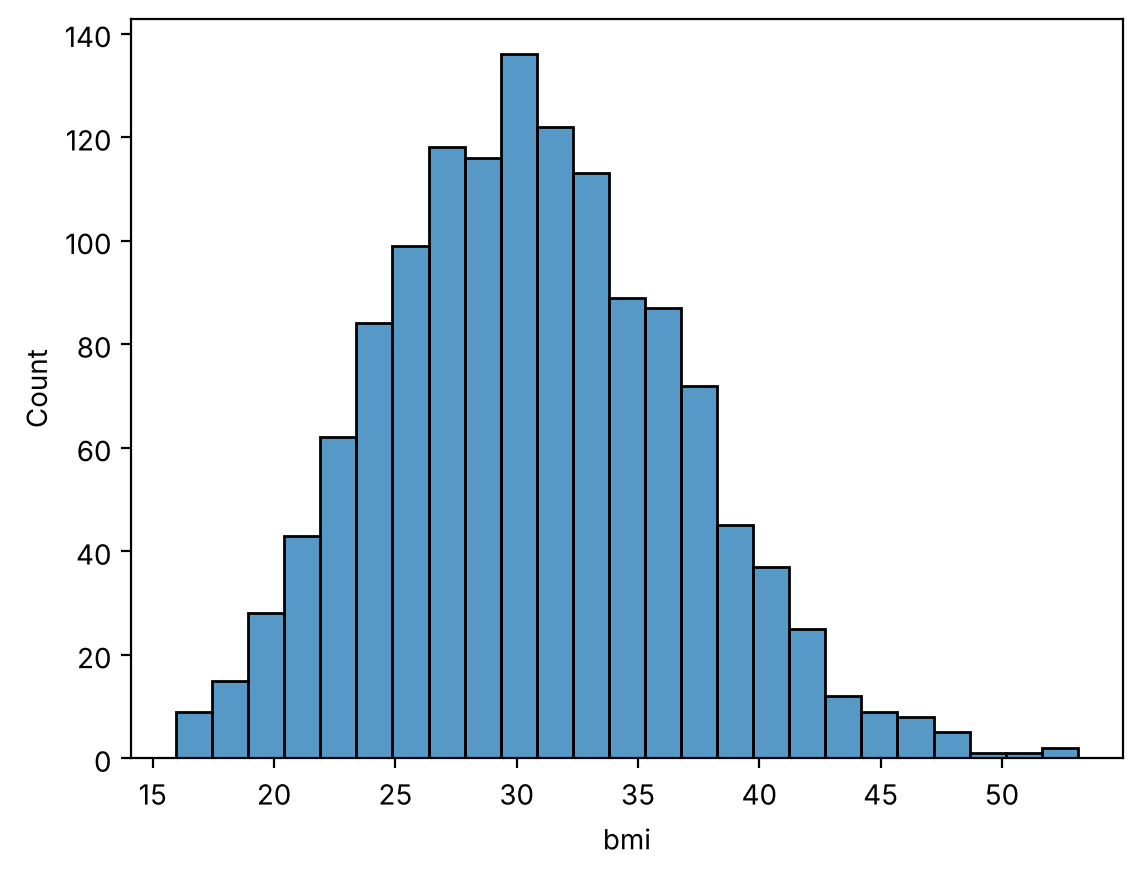

In [33]:
sns.histplot(df['bmi'])

### Creating BMI categories
Using the standard WHO BMI ranges: Underweight (< 18.5), Normal (18.5–24.9), Overweight (25–29.9), Obese (30+).

In [34]:
df_cleaned['bmi_category']=pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

In [35]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,1,0,Obese
2,28,0,33.000,3,0,4449.46200,0,1,0,Obese
3,33,0,22.705,0,0,21984.47061,1,0,0,Normal
4,32,0,28.880,0,0,3866.85520,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0,Obese
1334,18,1,31.920,0,0,2205.98080,0,0,0,Obese
1335,18,1,36.850,0,0,1629.83350,0,1,0,Obese
1336,21,1,25.800,0,0,2007.94500,0,0,1,Overweight


One-hot encoding the new `bmi_category` column (Underweight becomes the base category).

In [36]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['bmi_category'],drop_first=True)

In [37]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,1,16884.92400,0,0,1,False,True,False
1,18,0,33.770,1,0,1725.55230,0,1,0,False,False,True
2,28,0,33.000,3,0,4449.46200,0,1,0,False,False,True
3,33,0,22.705,0,0,21984.47061,1,0,0,True,False,False
4,32,0,28.880,0,0,3866.85520,1,0,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,1,0,0,False,False,True
1334,18,1,31.920,0,0,2205.98080,0,0,0,False,False,True
1335,18,1,36.850,0,0,1629.83350,0,1,0,False,False,True
1336,21,1,25.800,0,0,2007.94500,0,0,1,False,True,False


In [38]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='str')

### Feature scaling
`StandardScaler` brings `age`, `bmi` and `children` to the same scale (mean 0, standard deviation 1).

In [39]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']
scaler = StandardScaler()

df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

**Feature Selection**

### Pearson correlation
Measures the linear relationship between each feature and `charges` (-1 to +1). Closer to ±1 means a stronger relationship.

In [40]:
from scipy.stats import pearsonr
selected_features = ['age', 'bmi', 'children', 'is_female', 'is_smoker','region_northwest', 'region_southeast', 'region_southwest',
'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']

correlations = {feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
for feature in selected_features}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298308
1,bmi,0.198401
10,bmi_category_Obese,0.197659
6,region_southeast,0.073578
2,children,0.067389
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058044
8,bmi_category_Normal,-0.105655


**Observation:** `is_smoker` has by far the strongest relationship with charges (≈ 0.79), followed by `age` (≈ 0.30) and BMI. Sex, region and children have a weak relationship.

### Chi-square test (categorical features)
- **Null hypothesis (H0):** the feature and charges are independent.
- If **p-value < 0.05**, H0 is rejected, so the feature is related to charges.

Chi-square needs categories on both sides, so `charges` is split into 4 equal groups (quartiles).

In [41]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [42]:
from scipy.stats import chi2_contingency
import pandas as pd
alpha = 0.05
df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'], q=4, labels=False)
chi2_results = {}
for col in cat_features:
 contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
 chi2_stat, p_val, _, _ = chi2_contingency(contingency)
 decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
 chi2_results[col] = {'chi2_statistic': chi2_stat,'p_value': p_val,'Decision': decision}
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,7.654464,0.05372,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Normal,4.263673,0.234364,Accept Null (Drop Feature)
bmi_category_Overweight,4.201575,0.240504,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


### Final dataset
Selecting the final features for modelling. `bmi_category_Obese` is borderline in the Chi-square test (p ≈ 0.054), but it is kept because it has a clear correlation with charges (≈ 0.20).

In [43]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_category_Obese']]

In [44]:
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,False
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,1,True
2,-0.799350,0,0.383155,1.580143,0,4449.46200,1,True
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,False
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,False
...,...,...,...,...,...,...,...,...
1333,0.767704,0,0.050269,1.580143,0,10600.54830,0,True
1334,-1.511647,1,0.206053,-0.909234,0,2205.98080,0,True
1335,-1.511647,1,1.014490,-0.909234,0,1629.83350,1,True
1336,-1.297958,1,-0.797524,-0.909234,0,2007.94500,0,False


## Key Insights
1. **Smoking is the biggest factor.** Smokers pay about **3.8x more** on average than non-smokers, and `is_smoker` has the strongest correlation with charges (≈ 0.79).
2. **Charges increase with age.** Age is the second strongest factor (≈ 0.30).
3. **Higher BMI means higher charges.** Obese people pay more on average than people with normal BMI.
4. **Sex, region and number of children have a weak effect** on charges.
5. **`charges` is right-skewed**, so a log transform may help in the modelling stage.
